# SMC24 plasma diagnostics
## Problem and data
Recover four conditional electron-temperature/density pairs from author-published optical/IR emission-line observations. The source is a processed line compilation, not raw detector frames. No independent physical truth exists. The original standard-method result is an independent numerical reference. Atomic probabilities/energies/collision strengths are legitimate independent model calibration.
## Physics
For level i, incoming collisional and radiative population equals outgoing population, and fractional populations sum to1. Downward collisional rates are $q_{ji}=K\Upsilon/(g_j\sqrt T)$; upward rates multiply the Boltzmann and statistical-weight factors. Line emissivity is $p_jA_{ji}hc(E_j-E_i)10^8/n_e$. Here T is Kelvin, density is cm^-3, energies inverse Angstrom, and c is cm/s. All terms and numerical constants are defined in README.
## Method
Actively run local statistical equilibrium, CCM89 extinction and the original recursive30-section root search plus crossed Jacobi iteration. Each ratio root has fractional residual tolerance0.001 and at most20recursive refinements; outer iteration uses five updates and1percent relative condition changes. All four diagnostic combinations are evaluated. Seven original diagnostic groups remain in the temperature-density comparison. Shaded flux errors are assumed5percent, not measured detector noise. Mixed-ion disagreement is preserved rather than forced away.

In [1]:
import pathlib,os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
task=pathlib.Path.cwd()
if task.name=='notebooks':task=task.parent
os.chdir(task);sys.path.insert(0,str(task))
from src.main import run
from src.visualization import diagnostic_figure
from src.preprocessing import observation_ratios
from src.solvers import crossed_solution
start=time.perf_counter();conditions,ions,raw,corrected,ratios=run();runtime=time.perf_counter()-start
with np.load('notebooks/reference_outputs/upstream_original.npz',allow_pickle=False) as a:original=a['output_conditions'].copy()
print('Complete fresh reconstruction seconds:',runtime)
print('Pair order NII/OII,NII/SII,OIII/OII,OIII/SII; columns Kelvin, cm^-3')
print('Original:',original);print('Fresh:',conditions)


Complete fresh reconstruction seconds: 0.024380499962717295
Pair order NII/OII,NII/SII,OIII/OII,OIII/SII; columns Kelvin, cm^-3
Original: [[12223.74474458  5976.63314917]
 [12091.68937041  6888.48543244]
 [11487.02246948  5851.56631073]
 [11472.6711789   6764.74363699]]
Fresh: [[12223.74474458  5976.63314917]
 [12091.68937041  6888.48543244]
 [11487.02246948  5851.56631073]
 [11472.6711789   6764.74363699]]


## Observations and known extinction

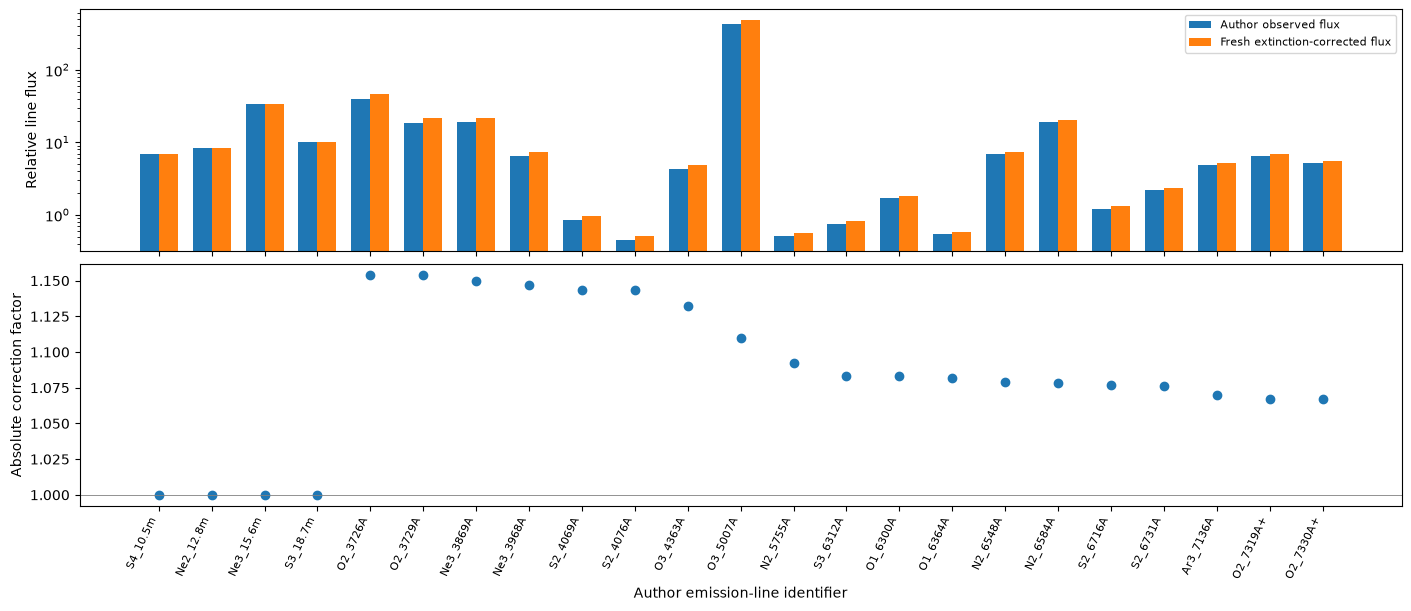

In [2]:
labels=list(raw);x=np.arange(len(labels))
fig,axs=plt.subplots(2,1,figsize=(14,6),layout='constrained',sharex=True)
axs[0].bar(x-.18,[raw[k] for k in labels],width=.36,label='Author observed flux')
axs[0].bar(x+.18,[corrected[k] for k in labels],width=.36,label='Fresh extinction-corrected flux')
axs[0].set(yscale='log',ylabel='Relative line flux');axs[0].legend(fontsize=8)
axs[1].plot(x,[corrected[k]/raw[k] for k in labels],'o');axs[1].axhline(1,color='gray',lw=.6)
axs[1].set(ylabel='Absolute correction factor',xlabel='Author emission-line identifier')
axs[1].set_xticks(x,labels,rotation=65,ha='right',fontsize=8)
fig.savefig('notebooks/reference_outputs/observations_review.png',dpi=140);plt.show()


## Results: all seven original diagnostic groups

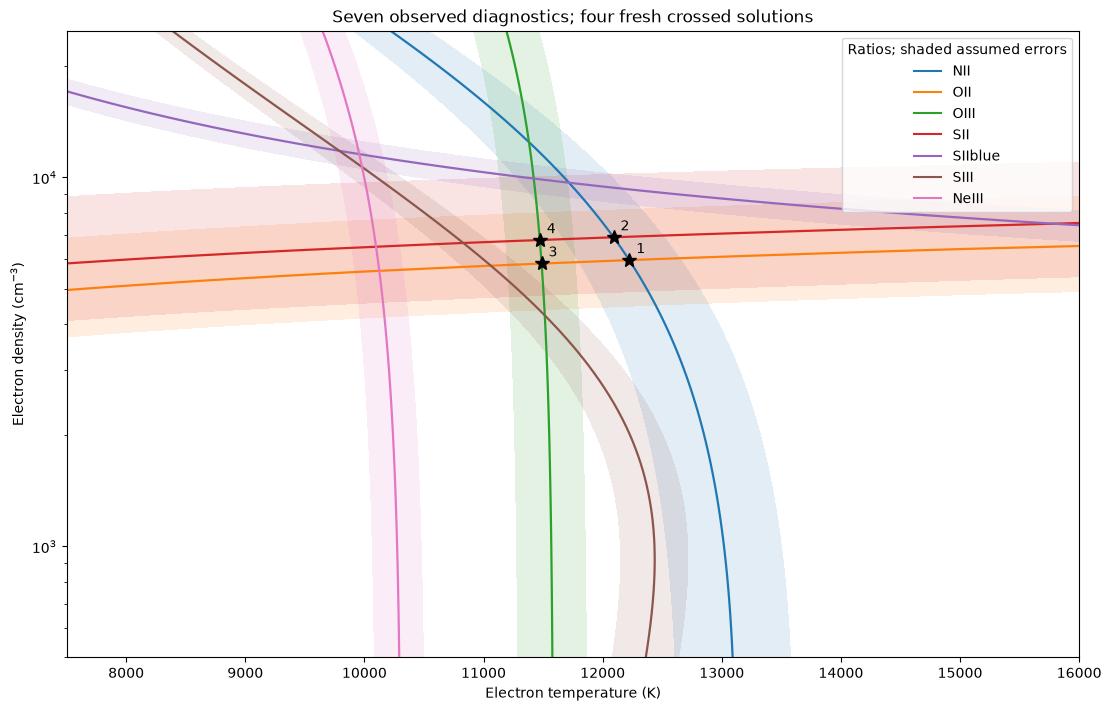

In [3]:
fig=diagnostic_figure(ions,ratios,conditions)
fig.savefig('notebooks/reference_outputs/diagnostics_review.png',dpi=140)
plt.show()


### Extinction and diagnostic-choice sensitivity: actual fresh reconstructions

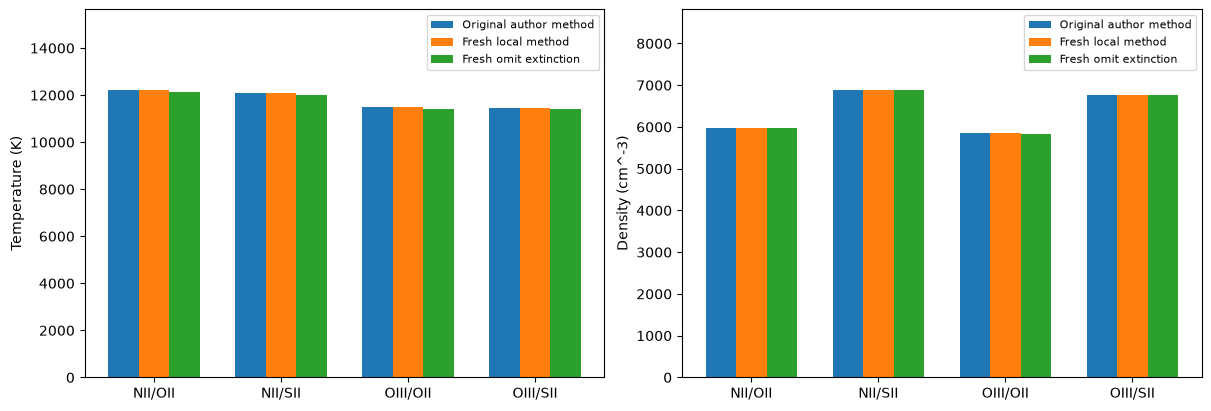

Omitting known extinction gives: [[12144.33945713  5976.63314917]
 [12013.14191296  6888.48543244]
 [11409.20333022  5833.91455391]
 [11388.54074379  6764.74363699]]
Relative original/fresh error: [0. 0.]


In [4]:
uncorrected_ratios=observation_ratios(raw)
uncorrected=np.array([crossed_solution(ions,t,n,uncorrected_ratios[t],uncorrected_ratios[n]) for t in ['NII','OIII'] for n in ['OII','SII']])
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained');x=np.arange(4);labels=['NII/OII','NII/SII','OIII/OII','OIII/SII']
for j,ax in enumerate(axs):
    ax.bar(x-.24,original[:,j],width=.24,label='Original author method')
    ax.bar(x,conditions[:,j],width=.24,label='Fresh local method')
    ax.bar(x+.24,uncorrected[:,j],width=.24,label='Fresh omit extinction')
    ax.set_xticks(x,labels);ax.set_ylabel(['Temperature (K)','Density (cm^-3)'][j]);ax.set_ylim(0,max(original[:,j].max(),conditions[:,j].max(),uncorrected[:,j].max())*1.28);ax.legend(fontsize=8,loc='upper right')
fig.savefig('notebooks/reference_outputs/conditions_review.png',dpi=140);plt.show()
print('Omitting known extinction gives:',uncorrected)
print('Relative original/fresh error:',np.max(np.abs(conditions/original-1),axis=0))


### Independent evaluator and conservation

In [5]:
import importlib.util
spec=importlib.util.spec_from_file_location('judge','evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate('output/reconstruction.npz');assert exitcode==0,report
print(json.dumps(report,indent=2))
for name,ion in ions.items():
    populations=ion.populations(12000.,6000.)
    print(name,'population sum',populations.sum(),'minimum',populations.min())
pathlib.Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps({'fresh_seconds':runtime,'conditions':conditions.tolist(),'uncorrected_conditions':uncorrected.tolist(),'judge':report},indent=2),encoding='utf8')


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "temperature_relative_error": 0.0,
    "density_relative_error": 0.0
  },
  "thresholds": {
    "temperature_relative_error": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "density_relative_error": {
      "comparison": "<=",
      "boundary": 0.0001
    }
  },
  "errors": []
}
N2 population sum 1.0 minimum 1.235834188468672e-09
O2 population sum 1.0 minimum 2.0669669795627124e-06
O3 population sum 1.0 minimum 4.916625895244323e-08
S2 population sum 1.0 minimum 3.0727618491783985e-05
S3 population sum 1.0 minimum 9.262758501236424e-07
Ne3 population sum 1.0 minimum 2.1434889949040435e-09


1000

## Conclusion
Fresh local equilibrium and crossed diagnostics reproduce the independent original outputs. Density differs between OII and SII diagnostics; temperature differs between NII and OIII. Those differences may reflect spatial ionization structure and model/atomic-data limitations. Extinction affects ratios and derived conditions; the omission experiment actually reconstructs the raw line ratios. No method reconstruction is called truth. Absolute uncertainties cannot be inferred from the assumed5percent visualization bands alone.